In [133]:
#installing important libraries
#%pip install pandas numpy matplotlib seaborn scikit-learn

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
DATA_DIR = Path("")
RUL_CAP = 125

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("Ready to begin.")
print("Dataset folder:", DATA_DIR.resolve())

Ready to begin.
Dataset folder: /Users/krishnashakya/Work/TATA_Elxsi_S4_PS1


In [134]:
columns = (
    ["unit_number", "time_cycles", "setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]
setting_cols = ["setting_1", "setting_2", "setting_3"]

train_path = DATA_DIR / "train_FD001.txt"
test_path = DATA_DIR / "test_FD001.txt"
rul_path = DATA_DIR / "RUL_FD001.txt"

for file in [train_path, test_path, rul_path]:
    if not file.exists():
        raise FileNotFoundError(
            f"Missing {file}. Put the three FD001 files in the folder"
            "next to this notebook, or change DATA_DIR."
        )

def load_cmapss(file_path):
    return pd.read_csv(file_path, sep=r"\s+", header=None, names=columns)

train_raw = load_cmapss(train_path)
test_raw = load_cmapss(test_path)
test_rul = pd.read_csv(rul_path, sep=r"\s+", header=None).iloc[:, 0].to_numpy()

print("Training data:", train_raw.shape)
print("Test data:", test_raw.shape)
print("Number of test RUL labels:", len(test_rul))
display(train_raw.head())

Training data: (20631, 26)
Test data: (13096, 26)
Number of test RUL labels: 100


,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [135]:

# Checks dataset size, unique engines, missing values, and duplicate rows.
# describe().T summarizes each column (mean, std, min/max, quartiles) to understand data distribution and identify constant sensors.
print("Training engines:", train_raw["unit_number"].nunique())
print("Test engines:", test_raw["unit_number"].nunique())
print("Missing values:", int(train_raw.isna().sum().sum()))
print("Duplicate rows:", int(train_raw.duplicated().sum()))

display(train_raw.describe().T.round(2))

Training engines: 100
Test engines: 100
Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
unit_number,20631.0,51.51,29.23,1.00,26.00,52.00,77.00,100.00
time_cycles,20631.0,108.81,68.88,1.00,52.00,104.00,156.00,362.00
setting_1,20631.0,-0.00,0.00,-0.01,-0.00,0.00,0.00,0.01
setting_2,20631.0,0.00,0.00,-0.00,-0.00,0.00,0.00,0.00
setting_3,20631.0,100.00,0.00,100.00,100.00,100.00,100.00,100.00
sensor_1,20631.0,518.67,0.00,518.67,518.67,518.67,518.67,518.67
sensor_2,20631.0,642.68,0.50,641.21,642.33,642.64,643.00,644.53
sensor_3,20631.0,1590.52,6.13,1571.04,1586.26,1590.10,1594.38,1616.91
sensor_4,20631.0,1408.93,9.00,1382.25,1402.36,1408.04,1414.55,1441.49
sensor_5,20631.0,14.62,0.00,14.62,14.62,14.62,14.62,14.62


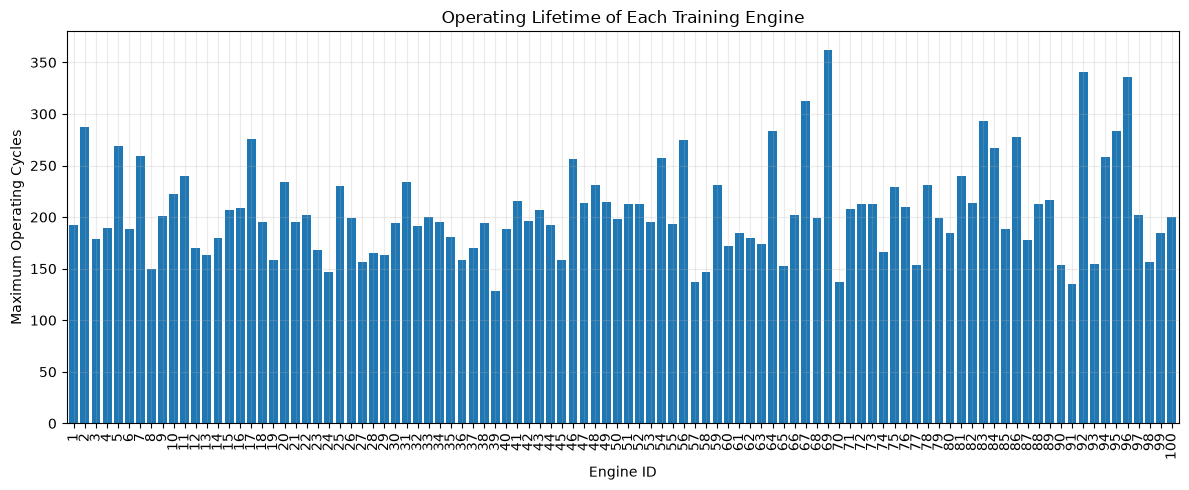

In [136]:
#The maximum cycle per engine shows how long each training engine was observed before its run-to-failure record ended.

# Find the maximum operating cycle reached by each training engine.
engine_lifetimes = train_raw.groupby("unit_number")["time_cycles"].max()

plt.figure(figsize=(12, 5))
engine_lifetimes.plot(kind="bar", width=0.8)

plt.title("Operating Lifetime of Each Training Engine")
plt.xlabel("Engine ID")
plt.ylabel("Maximum Operating Cycles")
plt.tight_layout()
plt.show()

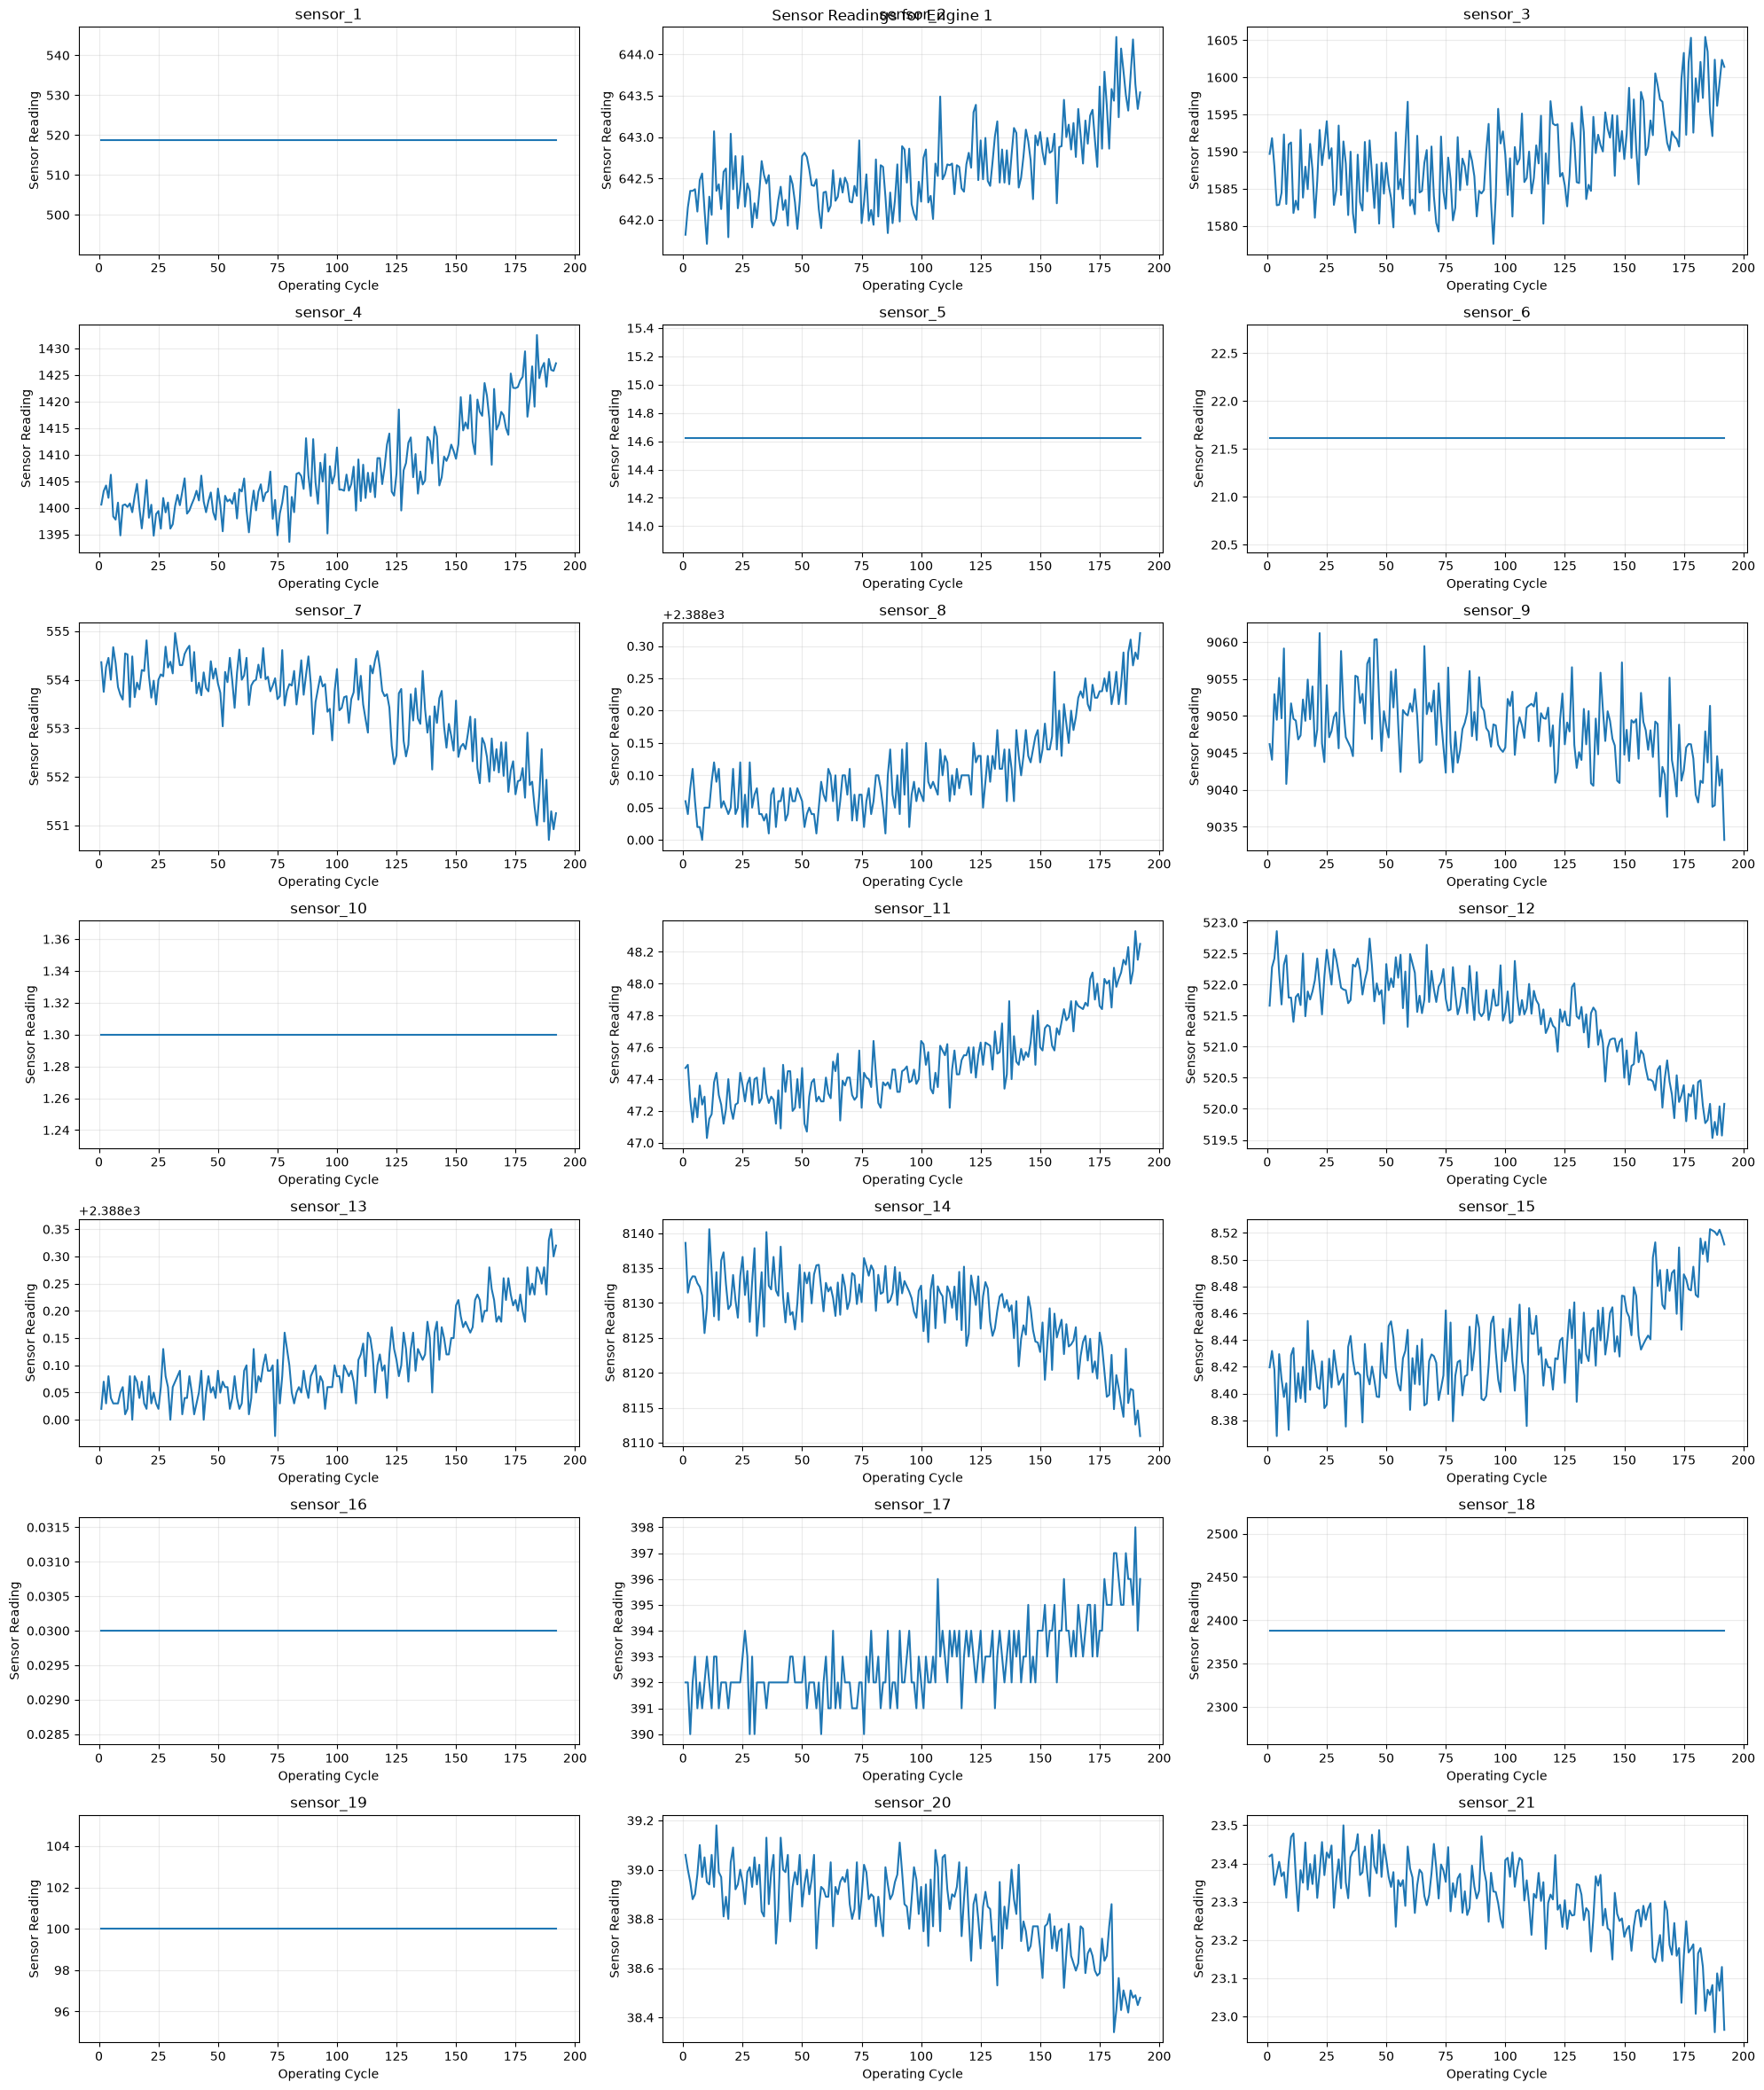

In [137]:
#Visualize sensor readings

# Sensor readings can change as an engine operates and degrades. Plotting sensor values over operating cycles helps us explore these trends.

# We will select one engine and plot a few sensor channels. These plots are exploratory: not every sensor necessarily shows a clear degradation pattern.

# Select one engine for visualization.
engine_id = 1

engine_data = train_raw[
    train_raw["unit_number"] == engine_id
].sort_values("time_cycles")

sensors_to_plot = [f"sensor_{i}" for i in range(1, 22)]

fig, axes = plt.subplots(7,3, figsize=(20, 24))
axes = axes.flatten()

for ax, sensor in zip(axes, sensors_to_plot):
    ax.plot(
        engine_data["time_cycles"],
        engine_data[sensor]
    )
    ax.set_ylabel("Sensor Reading")
    ax.set_xlabel("Operating Cycle")
    ax.set_title(sensor)

axes[-1].set_xlabel("Operating Cycle")
plt.suptitle(f"Sensor Readings for Engine {engine_id}")
plt.tight_layout()
plt.show()

In [138]:
# Map each numbered sensor to its standard C-MAPSS meaning.
sensor_dictionary = {
    "sensor_1":  {"symbol": "T2",       "description": "Total temperature at fan inlet",              "unit": "°R"},
    "sensor_2":  {"symbol": "T24",      "description": "Total temperature at low-pressure compressor outlet", "unit": "°R"},
    "sensor_3":  {"symbol": "T30",      "description": "Total temperature at high-pressure compressor outlet", "unit": "°R"},
    "sensor_4":  {"symbol": "T50",      "description": "Total temperature at low-pressure turbine outlet", "unit": "°R"},
    "sensor_5":  {"symbol": "P2",       "description": "Pressure at fan inlet",                       "unit": "psia"},
    "sensor_6":  {"symbol": "P15",      "description": "Total pressure in bypass duct",                "unit": "psia"},
    "sensor_7":  {"symbol": "P30",      "description": "Total pressure at high-pressure compressor outlet", "unit": "psia"},
    "sensor_8":  {"symbol": "Nf",       "description": "Physical fan rotational speed",                "unit": "rpm"},
    "sensor_9":  {"symbol": "Nc",       "description": "Physical core rotational speed",                "unit": "rpm"},
    "sensor_10": {"symbol": "epr",      "description": "Engine pressure ratio (P50/P2)",                "unit": "dimensionless"},
    "sensor_11": {"symbol": "Ps30",     "description": "Static pressure at high-pressure compressor outlet", "unit": "psia"},
    "sensor_12": {"symbol": "phi",      "description": "Ratio of fuel flow to Ps30",                    "unit": "pps/psi"},
    "sensor_13": {"symbol": "NRf",      "description": "Corrected fan rotational speed",                "unit": "rpm"},
    "sensor_14": {"symbol": "NRc",      "description": "Corrected core rotational speed",               "unit": "rpm"},
    "sensor_15": {"symbol": "BPR",      "description": "Bypass ratio",                                  "unit": "dimensionless"},
    "sensor_16": {"symbol": "farB",     "description": "Burner fuel-air ratio",                         "unit": "dimensionless"},
    "sensor_17": {"symbol": "htBleed",  "description": "Bleed enthalpy",                               "unit": "dataset-dependent"},
    "sensor_18": {"symbol": "Nf_dmd",   "description": "Demanded fan rotational speed",                 "unit": "rpm"},
    "sensor_19": {"symbol": "PCNfR_dmd","description": "Demanded corrected fan speed",                  "unit": "dataset-dependent"},
    "sensor_20": {"symbol": "W31",      "description": "High-pressure turbine coolant bleed flow",      "unit": "lbm/s"},
    "sensor_21": {"symbol": "W32",      "description": "Low-pressure turbine coolant bleed flow",       "unit": "lbm/s"},
}

sensor_dictionary_df = (
    pd.DataFrame.from_dict(sensor_dictionary, orient="index")
    .rename_axis("sensor_column")
    .reset_index()
)

display(sensor_dictionary_df)

,sensor_column,symbol,description,unit
0,sensor_1,T2,Total temperature at fan inlet,°R
1,sensor_2,T24,Total temperature at low-pressure compressor o...,°R
2,sensor_3,T30,Total temperature at high-pressure compressor ...,°R
3,sensor_4,T50,Total temperature at low-pressure turbine outlet,°R
4,sensor_5,P2,Pressure at fan inlet,psia
5,sensor_6,P15,Total pressure in bypass duct,psia
6,sensor_7,P30,Total pressure at high-pressure compressor outlet,psia
7,sensor_8,Nf,Physical fan rotational speed,rpm
8,sensor_9,Nc,Physical core rotational speed,rpm
9,sensor_10,epr,Engine pressure ratio (P50/P2),dimensionless


In [139]:
# Count the unique values in each sensor column.
sensor_unique_counts = train_raw[sensors_to_plot].nunique()

# Identify sensors that have only one unique value.
constant_sensors = sensor_unique_counts[
    sensor_unique_counts <= 1
].index.tolist()

constant_sensors.extend(["sensor_6",])

# Keep sensors that vary across the training dataset.
useful_sensors = [  
    sensor for sensor in sensors_to_plot
    if sensor not in constant_sensors
]

print("Constant sensors:", constant_sensors)

Constant sensors: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19', 'sensor_6']


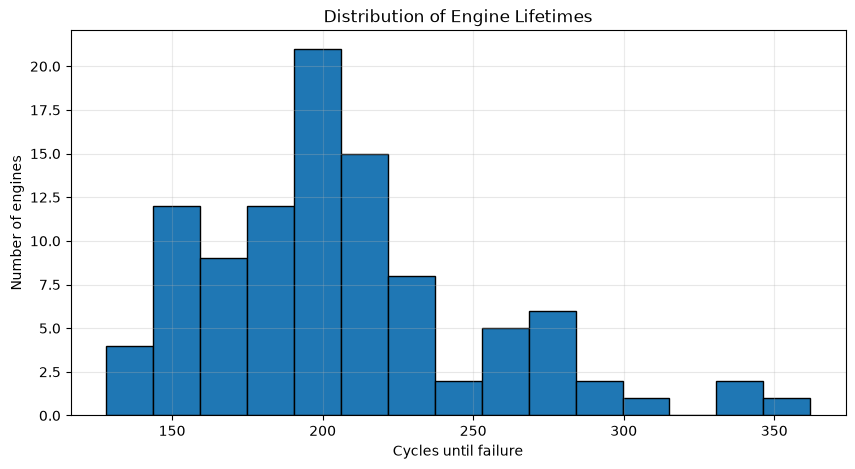

Shortest lifetime: 128
Longest lifetime: 362
Average lifetime: 206.31


In [140]:
engine_lifetimes = (
    train_raw.groupby("unit_number")["time_cycles"].max()
)

plt.figure(figsize=(10, 5))
plt.hist(engine_lifetimes, bins=15, edgecolor="black")
plt.title("Distribution of Engine Lifetimes")
plt.xlabel("Cycles until failure")
plt.ylabel("Number of engines")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Shortest lifetime:", engine_lifetimes.min())
print("Longest lifetime:", engine_lifetimes.max())
print("Average lifetime:", round(engine_lifetimes.mean(), 2))

In [141]:
train = train_raw.copy()

print("Training data loaded:", train.shape)


Training data loaded: (20631, 26)


,unit_number,time_cycles,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


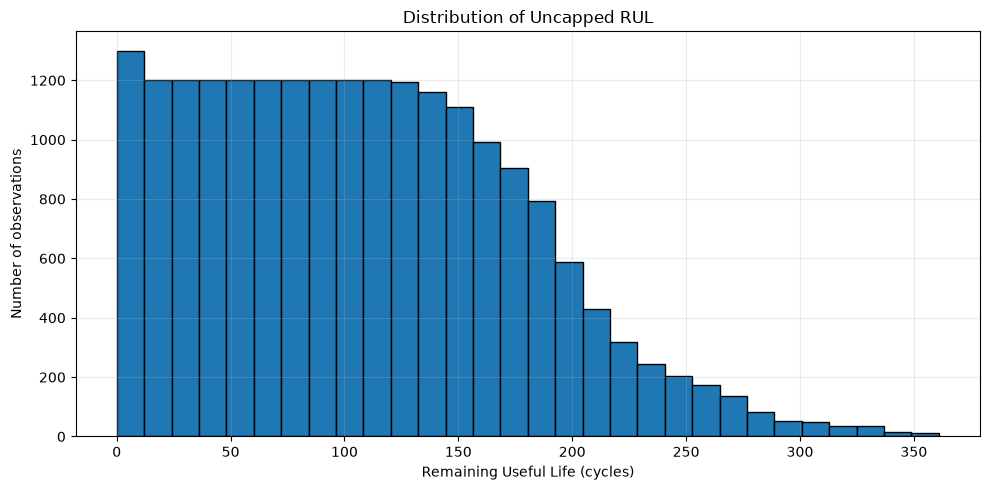

In [142]:
# Calculate uncapped Remaining Useful Life for each training row.
max_cycles = train.groupby("unit_number")["time_cycles"].max()

train["max_cycle"] = train["unit_number"].map(max_cycles)

train["RUL"] = train["max_cycle"] - train["time_cycles"]

display(
    train[["unit_number", "time_cycles", "max_cycle", "RUL"]].head(10)
)

plt.figure(figsize=(10, 5))
plt.hist(train["RUL"], bins=30, edgecolor="black")
plt.title("Distribution of Uncapped RUL")
plt.xlabel("Remaining Useful Life (cycles)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

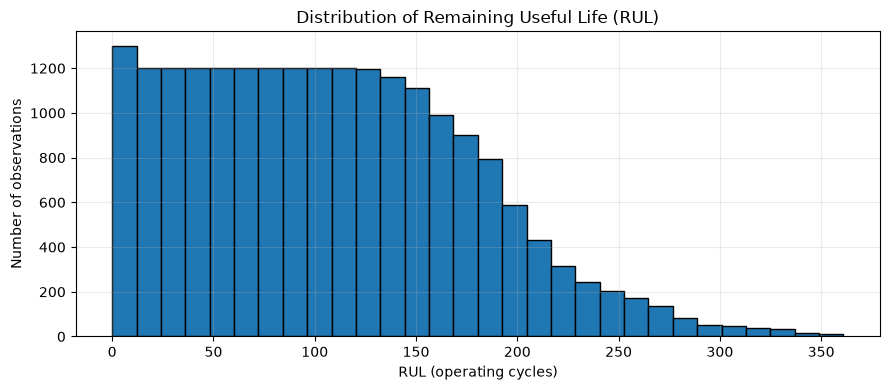

In [143]:
plt.figure(figsize=(9, 4))
plt.hist(train["RUL"], bins=30, edgecolor="black")

plt.title("Distribution of Remaining Useful Life (RUL)")
plt.xlabel("RUL (operating cycles)")
plt.ylabel("Number of observations")

plt.tight_layout()
plt.show()

## 8. Sliding-Window Feature Engineering

A sliding window uses recent sensor readings to capture short-term trends.

For a window size of 5 and a stride of 1, the windows move from cycles 1–5 to 2–6, then 3–7, and so on.

For each sensor, we calculate:
- Rolling mean: average of recent readings.
- Rolling standard deviation: variation in recent readings.

Windows are calculated separately for each engine and use only current and past readings.

In [144]:
WINDOW_SIZE = 5

def add_sliding_window_features(data, sensor_columns, window_size=5):
    data = data.sort_values(
        ["unit_number", "time_cycles"]
    ).copy()

    for sensor in sensor_columns:
        grouped = data.groupby("unit_number")[sensor]

        data[f"{sensor}_roll_mean"] = grouped.transform(
            lambda values: values.rolling(
                window_size, min_periods=1
            ).mean()
        )

        data[f"{sensor}_roll_std"] = grouped.transform(
            lambda values: values.rolling(
                window_size, min_periods=1
            ).std()
        )

    rolling_std_cols = [
        f"{sensor}_roll_std" for sensor in sensor_columns
    ]
    data[rolling_std_cols] = data[rolling_std_cols].fillna(0)

    return data

In [145]:
# Calculate rolling features for each engine's sensor readings.
train_windowed = add_sliding_window_features(
    train, useful_sensors, WINDOW_SIZE
)

test_windowed = add_sliding_window_features(
    test_raw, useful_sensors, WINDOW_SIZE
)

# Collect the names of the new rolling feature columns.
rolling_feature_cols = (
    [f"{sensor}_roll_mean" for sensor in useful_sensors]
    + [f"{sensor}_roll_std" for sensor in useful_sensors]
)

print("Window size:", WINDOW_SIZE)
print("Useful sensors:", len(useful_sensors))
print("Rolling features created:", len(rolling_feature_cols))

display(
    train_windowed[
        ["unit_number", "time_cycles"] + rolling_feature_cols[:]
    ].head(10)
)

Window size: 5
Useful sensors: 14
Rolling features created: 28


,unit_number,time_cycles,sensor_2_roll_mean,sensor_3_roll_mean,sensor_4_roll_mean,sensor_7_roll_mean,sensor_8_roll_mean,sensor_9_roll_mean,sensor_11_roll_mean,sensor_12_roll_mean,...,sensor_8_roll_std,sensor_9_roll_std,sensor_11_roll_std,sensor_12_roll_std,sensor_13_roll_std,sensor_14_roll_std,sensor_15_roll_std,sensor_17_roll_std,sensor_20_roll_std,sensor_21_roll_std
0,1,1,641.820000,1589.700000,1400.600000,554.360000,2388.0600,9046.190000,47.470,521.660,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,1,2,641.985000,1590.760000,1401.870000,554.055000,2388.0500,9045.130000,47.480,521.970,...,0.014142,1.499066,0.014142,0.438406,0.035355,5.041671,0.008697,0.000000,0.042426,0.003253
2,1,3,642.106667,1589.836667,1402.646667,554.123333,2388.0600,9047.733333,47.410,522.120,...,0.020000,4.632023,0.121655,0.404475,0.026458,3.717450,0.007640,1.154701,0.055076,0.044573
3,1,4,642.167500,1588.075000,1402.452500,554.205000,2388.0725,9048.170000,47.340,522.305,...,0.029861,3.881555,0.171659,0.495950,0.029439,3.050906,0.028117,1.000000,0.076322,0.037977
4,1,5,642.208000,1587.030000,1403.206000,554.164000,2388.0700,9049.566000,47.328,522.282,...,0.026458,4.587366,0.151063,0.432574,0.025884,2.651326,0.025953,1.095445,0.073621,0.033498
5,1,6,642.264000,1585.984000,1402.760000,554.226000,2388.0620,9050.264000,47.266,522.286,...,0.034928,4.193904,0.141527,0.425417,0.023452,0.958697,0.025727,1.140175,0.051186,0.031436
6,1,7,642.330000,1586.084000,1401.686000,554.344000,2388.0580,9053.276000,47.240,522.294,...,0.038987,4.038407,0.094074,0.425652,0.021679,0.643141,0.023476,1.140175,0.086718,0.021634
7,1,8,642.372000,1585.078000,1401.040000,554.262000,2388.0420,9050.848000,47.234,522.304,...,0.043818,6.915502,0.092628,0.429919,0.021679,1.149274,0.022477,0.836660,0.086487,0.034405
8,1,9,642.326000,1586.716000,1399.626000,554.110000,2388.0300,9050.244000,47.266,522.090,...,0.024495,7.191240,0.073348,0.341101,0.008944,3.205438,0.020740,0.836660,0.077136,0.038939
9,1,10,642.194000,1588.394000,1398.474000,554.028000,2388.0280,9049.554000,47.216,522.010,...,0.021679,6.755115,0.127004,0.358260,0.014142,2.883881,0.020493,0.836660,0.062849,0.058103


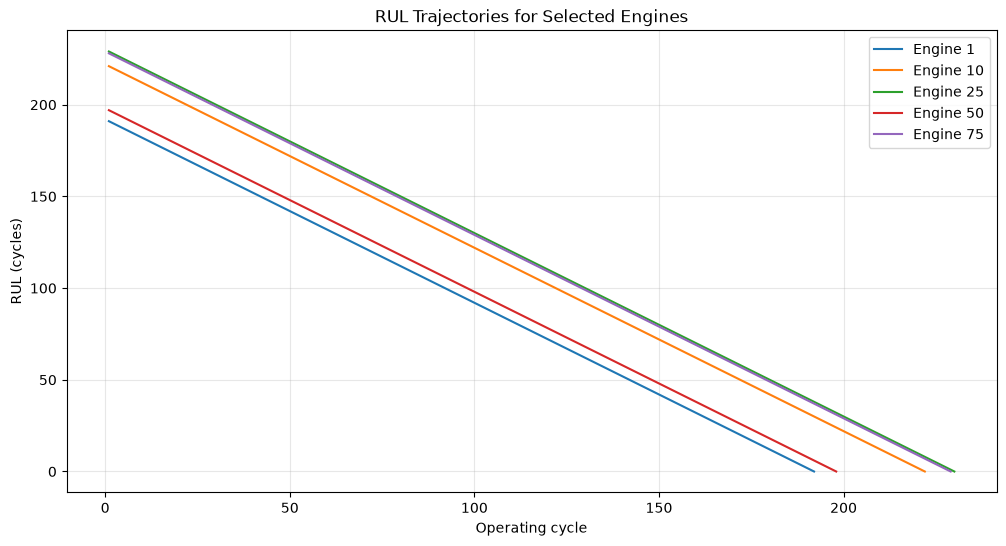

In [146]:
sample_engines = [1, 10, 25, 50, 75]

plt.figure(figsize=(12, 6))

for engine_id in sample_engines:
    engine_data = train[train["unit_number"] == engine_id]
    plt.plot(
        engine_data["time_cycles"],
        engine_data["RUL"],
        label=f"Engine {engine_id}"
    )

plt.title("RUL Trajectories for Selected Engines")
plt.xlabel("Operating cycle")
plt.ylabel("RUL (cycles)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

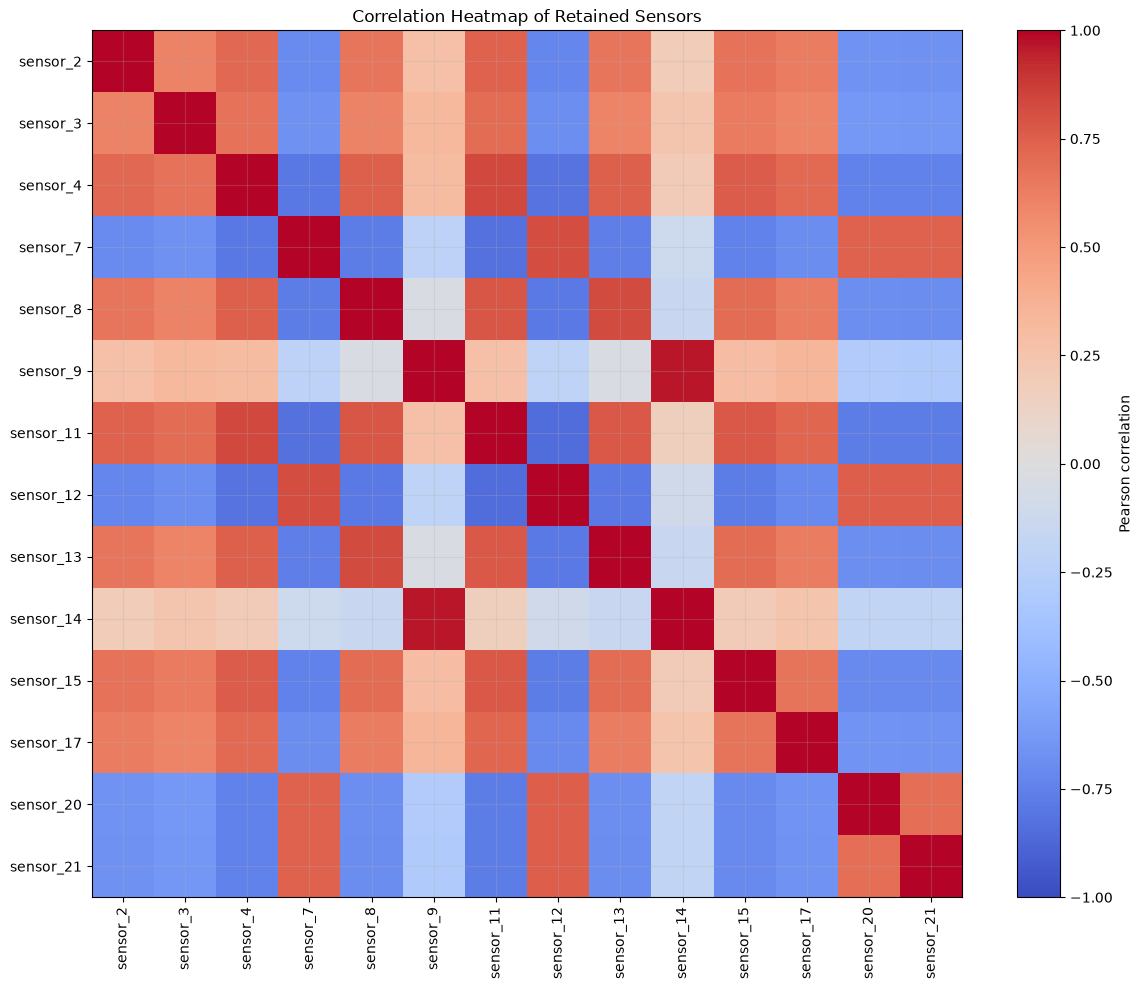

In [147]:
sensor_corr = train[useful_sensors].corr()

fig, ax = plt.subplots(figsize=(12, 10))

image = ax.imshow(
    sensor_corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(useful_sensors)))
ax.set_xticklabels(useful_sensors, rotation=90)
ax.set_yticks(range(len(useful_sensors)))
ax.set_yticklabels(useful_sensors)

ax.set_title("Correlation Heatmap of Retained Sensors")
fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

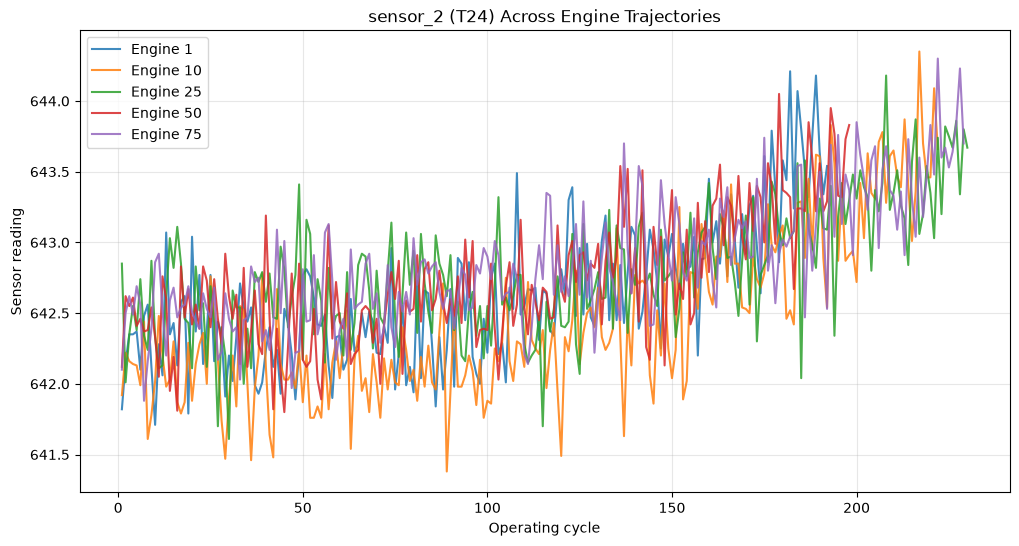

In [148]:
sensor_to_compare = useful_sensors[0]
sample_engines = [1, 10, 25, 50, 75]

fig, ax = plt.subplots(figsize=(12, 6))

for engine_id in sample_engines:
    engine_data = train[
        train["unit_number"] == engine_id
    ].sort_values("time_cycles")

    ax.plot(
        engine_data["time_cycles"],
        engine_data[sensor_to_compare],
        label=f"Engine {engine_id}",
        alpha=0.85
    )

sensor_info = sensor_dictionary.get(sensor_to_compare, {})
symbol = sensor_info.get("symbol", sensor_to_compare)
    
ax.set_title(
    f"{sensor_to_compare} ({symbol}) Across Engine Trajectories"
)
ax.set_xlabel("Operating cycle")
ax.set_ylabel("Sensor reading")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [149]:
# Use operating settings and rolling-window features as model inputs.
rolling_feature_cols = (
    [f"{sensor}_roll_mean" for sensor in useful_sensors]
    + [f"{sensor}_roll_std" for sensor in useful_sensors]
)

feature_cols = setting_cols + rolling_feature_cols

X = train_windowed[feature_cols]
y = train_windowed["RUL"]
groups = train_windowed["unit_number"]

# Split by engine so one engine cannot appear in both sets.
splitter = GroupShuffleSplit(
    test_size=0.2,
    n_splits=1,
    random_state=RANDOM_STATE
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]
y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Training engines:", groups.iloc[train_idx].nunique())
print("Validation engines:", groups.iloc[val_idx].nunique())
print("Number of features:", len(feature_cols))

Training rows: 16561
Validation rows: 4070
Training engines: 80
Validation engines: 20
Number of features: 31


## Train and Compare Regression Models

We train three models using the same training data and evaluate them on the same validation engines.

- Linear Regression: learns linear relationships between features and RUL.
- SVR: can learn nonlinear relationships using an RBF kernel.
- Random Forest: combines multiple decision trees to predict RUL.

We compare their MAE, RMSE, and R² scores to understand their performance.

In [150]:
# Define the three regression models.
models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),

    "SVR": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf")
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

results = []
predictions = {}

# Train and evaluate each model.
for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    predictions[name] = y_pred

    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    r2 = r2_score(y_val, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Display model comparison.
results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df.round(3))

Training Linear Regression...
Training SVR...
Training Random Forest...


,Model,MAE,RMSE,R2
2,Random Forest,24.337,34.156,0.729
1,SVR,27.659,38.145,0.662
0,Linear Regression,29.598,37.575,0.672


In [151]:
# Select the last observed cycle for each test engine.
test_last = (
    test_windowed
    .sort_values(["unit_number", "time_cycles"])
    .groupby("unit_number")
    .tail(1)
    .sort_values("unit_number")
    .reset_index(drop=True)
)

# Actual uncapped RUL from the official NASA labels.
y_test = test_rul.copy()

# Prepare features for the test engines.
X_test = test_last[feature_cols]

print("Test engines:", len(test_last))
print("Test features shape:", X_test.shape)
print("Actual RUL labels:", len(y_test))

display(
    test_last[["unit_number", "time_cycles"]].head()
)

Test engines: 100
Test features shape: (100, 31)
Actual RUL labels: 100


,unit_number,time_cycles
0,1,31
1,2,49
2,3,126
3,4,106
4,5,98


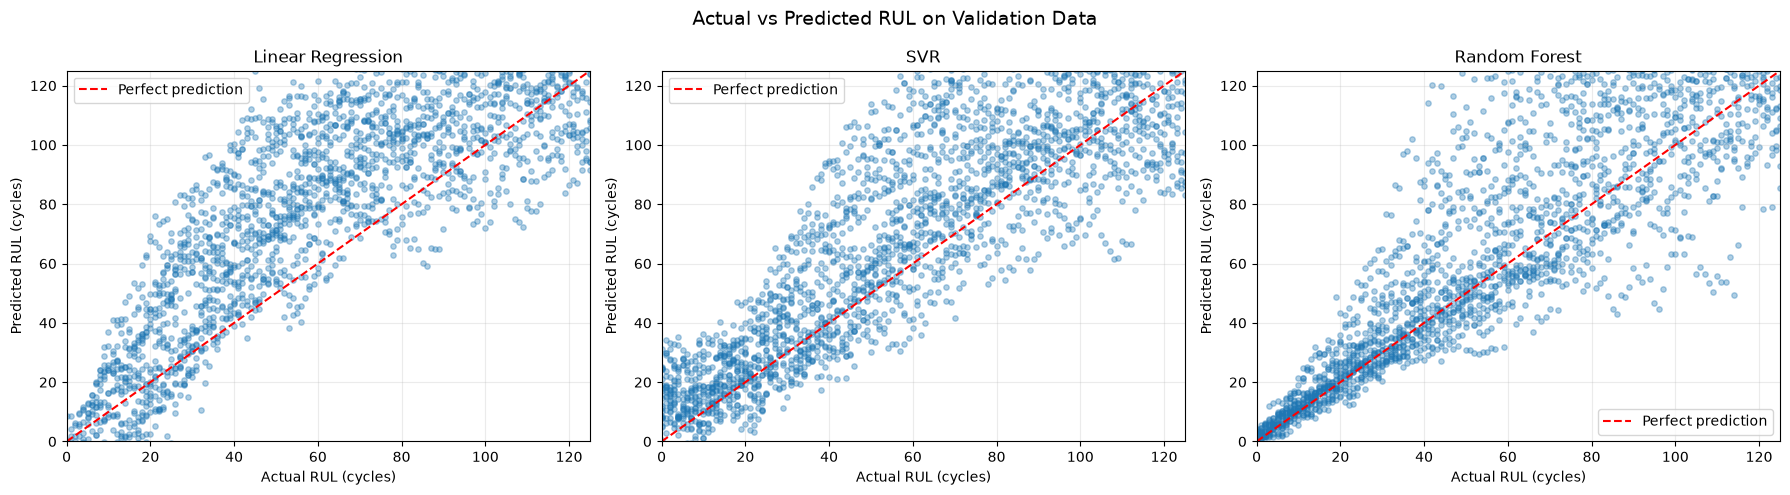

In [152]:
# Plot predictions from all three models.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_val, y_pred, alpha=0.35, s=15)

    # Reference line: perfect predictions.
    ax.plot(
        [0, RUL_CAP],
        [0, RUL_CAP],
        "r--",
        label="Perfect prediction"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual RUL (cycles)")
    ax.set_ylabel("Predicted RUL (cycles)")
    ax.set_xlim(0, RUL_CAP)
    ax.set_ylim(0, RUL_CAP)
    ax.legend()

plt.suptitle("Actual vs Predicted RUL on Validation Data", fontsize=14)
plt.tight_layout()
plt.show()